## Exploratory Data Analysis (METABRIC Dataset)

**Goals:**
1. Load and understand the shape/types of the data.
2. Identify missing values and categorical vs. continuous features.
3. Explore basic univariate distributions.
4. Formulate initial hypotheses for clustering and dimensionality reduction.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set display options for large datasets
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

### 1. Data Loading & Initial Inspection

In [3]:
# Load the dataset
df = pd.read_csv('METABRIC_RNA_Mutation.csv', low_memory=False)

print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (1904, 693)


,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,er_status,neoplasm_histologic_grade,her2_status_measured_by_snp6,her2_status,tumor_other_histologic_subtype,hormone_therapy,inferred_menopausal_state,integrative_cluster,primary_tumor_laterality,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,oncotree_code,overall_survival_months,overall_survival,...,foxo1_mut,nt5e_mut,ccnd3_mut,nr3c1_mut,prkg1_mut,tbl1xr1_mut,frmd3_mut,smad2_mut,sgcd_mut,spaca1_mut,rasgef1b_mut,hist1h2bc_mut,nr2f1_mut,klrg1_mut,mbl2_mut,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Ductal/NST,1,Post,4ER+,Right,10.0,NaN,6.044,IDC,140.500000,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Ductal/NST,1,Pre,4ER+,Right,0.0,2.0,4.020,IDC,84.633333,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,Positive,2.0,NEUTRAL,Negative,Ductal/NST,1,Pre,3,Right,1.0,2.0,4.030,IDC,163.700000,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,Positive,2.0,NEUTRAL,Negative,Mixed,1,Pre,9,Right,3.0,1.0,4.050,MDLC,164.933333,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,Positive,3.0,NEUTRAL,Negative,Mixed,1,Post,9,Right,8.0,2.0,6.080,MDLC,41.366667,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
# separate numerical and categorical columns for analysis
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Number of numerical columns: {len(numerical_cols)}")
print(f"Number of categorical columns: {len(categorical_cols)}")

# let's look at a few examples of each
print("\nSample Numerical Columns:", numerical_cols[:10])
print("\nSample Categorical Columns:", categorical_cols[:10])

Number of numerical columns: 503
Number of categorical columns: 190

Sample Numerical Columns: ['patient_id', 'age_at_diagnosis', 'chemotherapy', 'cohort', 'neoplasm_histologic_grade', 'hormone_therapy', 'lymph_nodes_examined_positive', 'mutation_count', 'nottingham_prognostic_index', 'overall_survival_months']

Sample Categorical Columns: ['type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'pam50_+_claudin-low_subtype', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype']


### 2. Missing Values Analysis
Understanding which features have the most missing data will dictate our cleaning strategy (imputation vs. dropping).

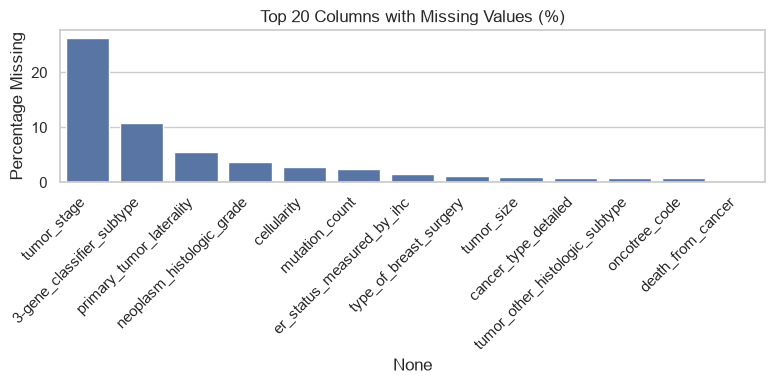

In [5]:
# Calculate percentage of missing values per column
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

# Plot top 20 columns with missing values
if not missing_percent.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_percent.head(20).index, y=missing_percent.head(20).values)
    plt.xticks(rotation=45, ha='right')
    plt.title('Top 20 Columns with Missing Values (%)')
    plt.ylabel('Percentage Missing')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found!")

### 3. Data Cleaning and preprocessing

In [6]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Drop columns with excessive missing data (> 40%)
threshold = 0.2
missing_fraction = df.isnull().mean()
cols_to_drop = missing_fraction[missing_fraction > threshold].index
df_cleaned = df.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns due to >20% missing data.")

# Separate features (X) and target (y)
# Adjust 'target_col' if you are predicting something else (e.g., 'overall_survival_months')
target_col = 'overall_survival'
X = df_cleaned.drop(columns=[target_col])
y = df_cleaned[target_col]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Build preprocessing pipelines
# Numerical: Impute missing values with the median, then scale to mean=0, variance=1
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# One hot encode
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# combine pipelines into a ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit and transform the feature matrix
X_processed = preprocessor.fit_transform(X)

# Reconstruct a Pandas DataFrame for downstream EDA and Feature Selection
# Retrieve new column names post-encoding
cat_feature_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(cat_feature_names)

X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names, index=X.index)

print(f"Original shape: {df.shape}")
print(f"Processed shape: {X_processed_df.shape}")
display(X_processed_df.head())

Dropped 1 columns due to >20% missing data.
Original shape: (1904, 693)
Processed shape: (1904, 8499)


,patient_id,age_at_diagnosis,chemotherapy,cohort,neoplasm_histologic_grade,hormone_therapy,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,overall_survival_months,radio_therapy,tumor_size,brca1,brca2,palb2,pten,tp53,atm,cdh1,chek2,nbn,nf1,stk11,bard1,mlh1,...,smarcd1_mut_M366T,smarcd1_mut_N84S,smarcd1_mut_P78R,nras_mut_0,nras_mut_D108N,nras_mut_G12S,nras_mut_T124A,ndfip1_mut_0,ndfip1_mut_A50T,ndfip1_mut_N68S,ndfip1_mut_X51_splice,hras_mut_0,hras_mut_N86T,hras_mut_Q61R,prps2_mut_0,prps2_mut_G255R,prps2_mut_I159F,smarcb1_mut_0,smarcb1_mut_D159N,smarcb1_mut_I28L,stmn2_mut_0,stmn2_mut_N145K,stmn2_mut_R156H,siah1_mut_0,siah1_mut_T249A
0,-1.663366,1.122359,-0.512445,-1.338368,0.867685,0.788547,1.960788,-0.169839,1.757557,0.201518,0.821330,-0.278813,-1.399001,-0.573800,-1.6217,1.452401,0.350399,1.151701,0.034798,0.1266,-0.836099,-0.857800,-0.429399,-1.120101,-0.484399,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-1.662518,-1.379317,-0.512445,-1.338368,0.867685,0.788547,-0.490841,-0.917810,-0.011378,-0.530544,0.821330,-1.074529,-1.380001,0.277701,-1.2154,0.529601,-0.013601,-0.265900,1.359398,0.7961,0.541900,-2.605901,0.512000,0.439000,1.226601,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.661245,-0.941562,1.951430,-1.338368,-0.676308,0.788547,-0.245678,-0.917810,-0.002638,0.505525,-1.217538,-0.742981,0.067001,-0.842600,0.2114,-0.332599,0.514099,-0.080300,1.139798,0.4187,-0.402999,-1.130500,0.236200,-0.172101,-1.790999,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-1.660821,-1.033275,1.951430,-1.338368,-0.676308,0.788547,0.244648,-1.167134,0.014841,0.521686,0.821330,-0.079884,0.674401,-0.542800,-1.6592,0.636901,1.670799,-0.888000,1.249098,-1.1889,-0.417399,-0.616499,1.007800,-0.401001,-1.390499,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-1.659973,1.224091,1.951430,-1.338368,0.867685,0.788547,1.470462,-0.917810,1.789021,-1.097499,0.821330,0.914762,1.293202,-0.903900,-0.7219,0.216801,0.348399,0.389700,0.913098,0.9356,0.767500,-0.293999,-0.296099,0.632000,-0.358199,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


### 4. Target Definition & Clinical Overview
Before looking at gene expression, let's look at the clinical attributes (e.g., survival status, cancer subtype, age). These will likely be our 'target' variables for color-coding our Dash plots.

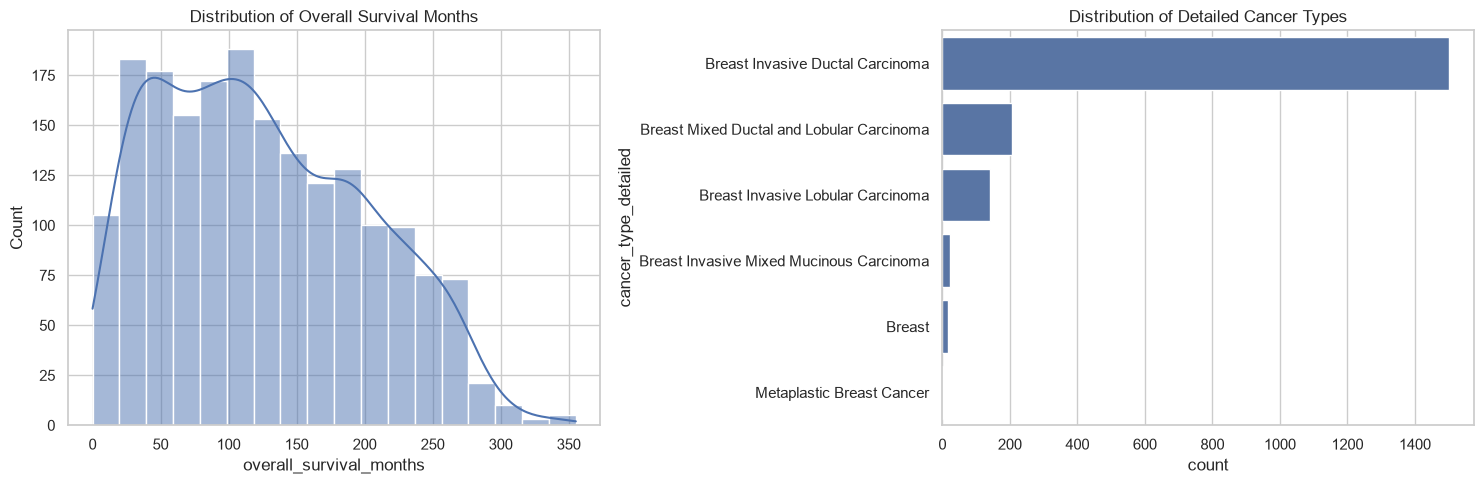

In [7]:
# let's examine the distribution of Patient Survival Status and Cancer Subtype
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Survival Status (we will use 'overall_survival_months' for numerical, and need to find the exact categorical column for death status)
sns.histplot(data=df, x='overall_survival_months', kde=True, ax=axes[0])
axes[0].set_title('Distribution of Overall Survival Months')

# sssuming there is a 'cancer_type_detailed' column based on standard METABRIC data
if 'cancer_type_detailed' in df.columns:
    sns.countplot(data=df, y='cancer_type_detailed', order=df['cancer_type_detailed'].value_counts().index, ax=axes[1])
    axes[1].set_title('Distribution of Detailed Cancer Types')

plt.tight_layout()
plt.show()

### 5. Target Definition


In [8]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler

# Define your ground-truth target for coloring (e.g., cancer type or survival status)
target_col = 'overall_survival' 
hover_cols = ['patient_id', 'age_at_diagnosis', 'cancer_type_detailed']

In [ ]:
# prototype EDA Distributions (Histogram & Violin)
def plot_feature_distribution(df, feature, n_bins=30):
    # Overlayed Histogram
    fig_hist = px.histogram(
        df, x=feature, color=target_col, 
        nbins=n_bins, barmode='overlay',
        title=f'{feature} Distribution by {target_col}',
        hover_data=hover_cols
    )
    # Customize hovertemplate to prove understanding of precise hover data
    fig_hist.update_traces(
        hovertemplate="<b>%{customdata[0]}</b><br>Value: %{x}<br>Age: %{customdata[1]}<br>Type: %{customdata[2]}<extra></extra>"
    )
    fig_hist.show()

    # Violin Plot for separability
    fig_violin = px.violin(
        df, y=feature, color=target_col, box=True, points="all",
        title=f'{feature} Separability',
        hover_data=hover_cols
    )
    fig_violin.show()

# Test the prototype
plot_feature_distribution(df, 'mutation_count', n_bins=50)

### 6. Feature Relationships & Selection

In [ ]:
# cell 3: Prototyping Heatmaps & Scatter Matrix
# select a subset of numerical features for testing
features = numerical_cols[:10] 
X = df[features].fillna(0)

# Pearson Correlation Heatmap (Diverging scale)
corr_matrix = X.corr().round(2)
fig_corr = ff.create_annotated_heatmap(
    z=corr_matrix.values, x=list(corr_matrix.columns), y=list(corr_matrix.index),
    colorscale='RdBu', zmin=-1, zmax=1, showscale=True
)
fig_corr.update_layout(title='Pearson Correlation (RdBu)')
fig_corr.show()

# Mutual Information Heatmap (Sequential scale)
mi_scores = mutual_info_classif(X, df[target_col].fillna(0))
# Reshape for heatmap visualization against the target
fig_mi = px.imshow(
    [mi_scores], x=features, y=['Mutual Info'], text_auto=True, color_continuous_scale='YlGnBu',
    title='Mutual Information with Target'
)
fig_mi.show()

# Interactive Scatter Matrix
fig_scatter = px.scatter_matrix(
    df, dimensions=features[:4], color=target_col,
    hover_data=['patient_id'],
    title="Scatter Matrix (Use Plotly Lasso Tool to select points)"
)
fig_scatter.update_traces(diagonal_visible=False)
fig_scatter.show()

### 7. Dimensionality Reduction 

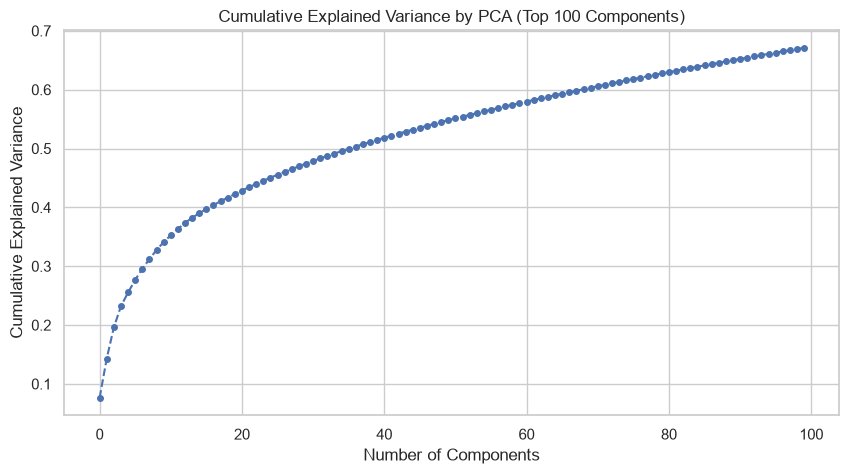

Calculating Mutual Information scores (this may take a few seconds)...


C:\Users\renan\AppData\Local\Temp\ipykernel_24988\184589512.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_scores_series.head(20).values, y=mi_scores_series.head(20).index, palette='viridis')


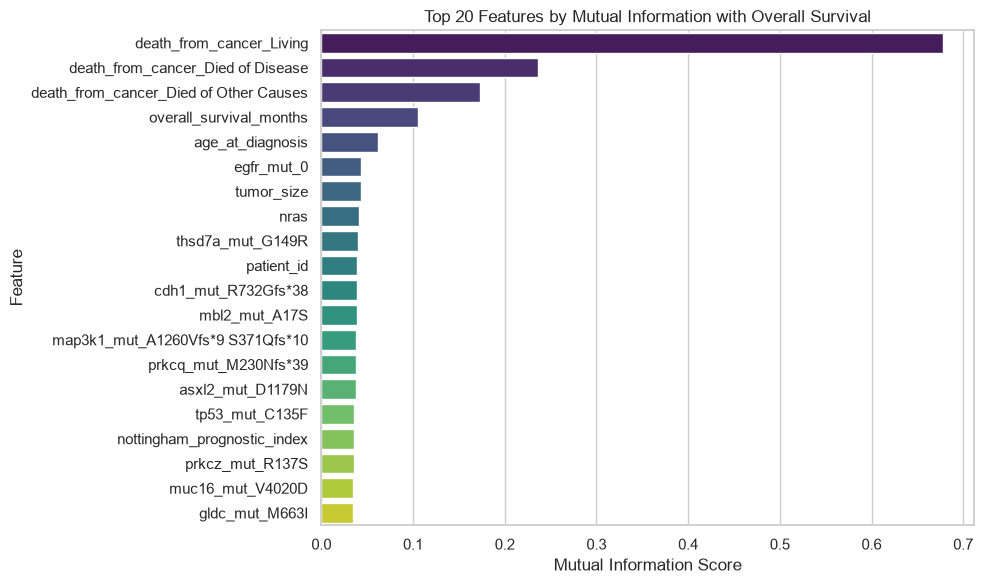


Top 10 Predictive Features:


death_from_cancer_Living                  0.677837
death_from_cancer_Died of Disease         0.236186
death_from_cancer_Died of Other Causes    0.172643
overall_survival_months                   0.105508
age_at_diagnosis                          0.062160
egfr_mut_0                                0.043557
tumor_size                                0.042748
nras                                      0.041421
thsd7a_mut_G149R                          0.039502
patient_id                                0.039351
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

# Dimensionality Reduction (PCA)
# Evaluate how many components are needed to explain the variance
pca = PCA()
X_pca = pca.fit_transform(X_processed_df)

plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_[:100]), marker='o', linestyle='--', markersize=4)
plt.title('Cumulative Explained Variance by PCA (Top 100 Components)')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

# Feature Selection (Mutual Information)
# Rank features by their relationship with overall_survival to establish baselines
print("Calculating Mutual Information scores (this may take a few seconds)...")
mi_scores = mutual_info_classif(X_processed_df, y, random_state=42)
mi_scores_series = pd.Series(mi_scores, index=X_processed_df.columns).sort_values(ascending=False)

# plot top 20 features
plt.figure(figsize=(10, 6))
sns.barplot(x=mi_scores_series.head(20).values, y=mi_scores_series.head(20).index, palette='viridis')
plt.title('Top 20 Features by Mutual Information with Overall Survival')
plt.xlabel('Mutual Information Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Display the exact scores for the top 10
print("\nTop 10 Predictive Features:")
display(mi_scores_series.head(10))

### Addressing Data Leakage and Establishing a Baseline
- The Mutual Information scores reveal a critical flaw in the current feature set: data leakage. Top-ranking features such as death_from_cancer and overall_survival_months are direct proxies for our target variable (overall_survival). In a real-world clinical setting, these metrics are entirely unknown at the time of diagnosis. Training a model with them would yield near-perfect, yet completely unapplicable, results. Additionally, patient_id is a purely unique identifier that adds noise rather than predictive value. These columns must be removed.

- Furthermore, the PCA cumulative variance plot demonstrated that the dataset's variance is highly distributed across hundreds of components without a sharp flattening "elbow." Rather than aggressively truncating the data with PCA, which risks discarding subtle but important genomic signals, we will establish a linear baseline using Logistic Regression with an L1 penalty (Lasso).

- L1 regularization is particularly well-suited for high-dimensional bioinformatics datasets. It performs embedded feature selection by driving the coefficients of irrelevant genes and clinical metrics to exactly zero, producing a sparse, interpretable model without requiring manual feature dropping.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Remove Data Leakage and Identifiers
# Identify columns that perfectly predict the target or act as unique IDs
leaky_cols = [col for col in X_processed_df.columns if 'death_from_cancer' in col]
leaky_cols += ['overall_survival_months', 'patient_id']

cols_to_drop = [col for col in leaky_cols if col in X_processed_df.columns]
X_clean = X_processed_df.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} leaky/identifier columns: {cols_to_drop}")

# 2. Train-Test Split (Stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Establish a Linear Baseline 
# L1 regularization (Lasso) acts as feature selection, driving irrelevant feature weights to exactly zero
baseline_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

# 4. Evaluate Baseline Performance
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("\n--- Linear Baseline Performance (Logistic Regression L1) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

# 5. Inspect Embedded Feature Selection
kept_features = sum(baseline_model.coef_[0] != 0)
print(f"\nFeatures retained by L1 regularization: {kept_features} out of {X_train.shape[1]}")

Dropped 5 leaky/identifier columns: ['death_from_cancer_Died of Disease', 'death_from_cancer_Died of Other Causes', 'death_from_cancer_Living', 'overall_survival_months', 'patient_id']


c:\Users\renan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\renan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(



--- Linear Baseline Performance (Logistic Regression L1) ---
              precision    recall  f1-score   support

           0       0.69      0.69      0.69       221
           1       0.57      0.58      0.58       160

    accuracy                           0.64       381
   macro avg       0.63      0.63      0.63       381
weighted avg       0.64      0.64      0.64       381

ROC-AUC Score: 0.6562

Features retained by L1 regularization: 554 out of 8494


Removed 0 residual identifier columns.
New feature count for Random Forest: 8494

--- Non-Linear Performance (Random Forest) ---
              precision    recall  f1-score   support

           0       0.69      0.74      0.71       221
           1       0.60      0.54      0.57       160

    accuracy                           0.65       381
   macro avg       0.64      0.64      0.64       381
weighted avg       0.65      0.65      0.65       381

ROC-AUC Score: 0.6936


C:\Users\renan\AppData\Local\Temp\ipykernel_24988\416564012.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances_sorted.values, y=importances_sorted.index, palette='magma')


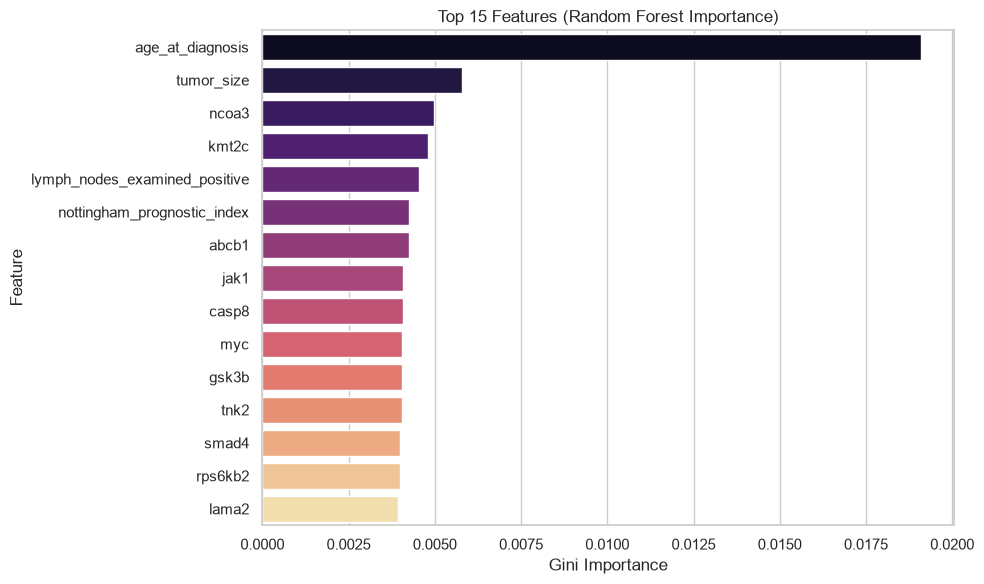

In [12]:
from sklearn.ensemble import RandomForestClassifier

# 1. Clean up the exploded ID columns created by One-Hot Encoding
id_cols = [col for col in X_train.columns if 'patient_id' in col.lower()]
X_train_clean = X_train.drop(columns=id_cols)
X_test_clean = X_test.drop(columns=id_cols)

print(f"Removed {len(id_cols)} residual identifier columns.")
print(f"New feature count for Random Forest: {X_train_clean.shape[1]}")

# 2. Train a Non-Linear Ensemble Model
rf_model = RandomForestClassifier(
    n_estimators=200, 
    max_depth=10,        # Constrained depth to prevent overfitting the noise
    min_samples_leaf=4, 
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1            # Use all CPU cores
)

rf_model.fit(X_train_clean, y_train)

# 3. Evaluate Random Forest Performance
y_pred_rf = rf_model.predict(X_test_clean)
y_proba_rf = rf_model.predict_proba(X_test_clean)[:, 1]

print("\n--- Non-Linear Performance (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_rf):.4f}")

# 4. Visualize Top 15 Non-Linear Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=X_train_clean.columns)
importances_sorted = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances_sorted.values, y=importances_sorted.index, palette='magma')
plt.title('Top 15 Features (Random Forest Importance)')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

- The transition from a penalized linear baseline to a Random Forest ensemble allows us to capture complex, non-linear interactions within the high-dimensional clinical and genomic space. The resulting feature importance distribution highlights a stark hierarchy in predictive power.

- Foundational physiological and clinical metrics—most notably age_at_diagnosis, followed by tumor_size, lymph_nodes_examined_positive, and the nottingham_prognostic_index—overwhelmingly dominate the model's decision-making process. While specific genomic markers (such as ncoa3 and kmt2c expressions) break into the top tier of predictive features, their overall Gini importance remains marginal compared to the macroscopic clinical indicators.

- However, relying solely on standard tree-based impurity metrics presents a structural limitation, beacuse Gini importance is inherently biased toward continuous variables with high cardinality, such as age, and lacks directional context (it does not indicate whether a feature increases or decreases survival probability). To extract mathematically rigorous and clinically actionable insights, the architecture must transition from basic feature ranking to individual-level prediction explainability.


--- Gradient Boosting Performance (XGBoost) ---
              precision    recall  f1-score   support

           0       0.75      0.75      0.75       221
           1       0.65      0.65      0.65       160

    accuracy                           0.71       381
   macro avg       0.70      0.70      0.70       381
weighted avg       0.71      0.71      0.71       381

ROC-AUC Score: 0.7466

Calculating SHAP values (this may take a moment)...


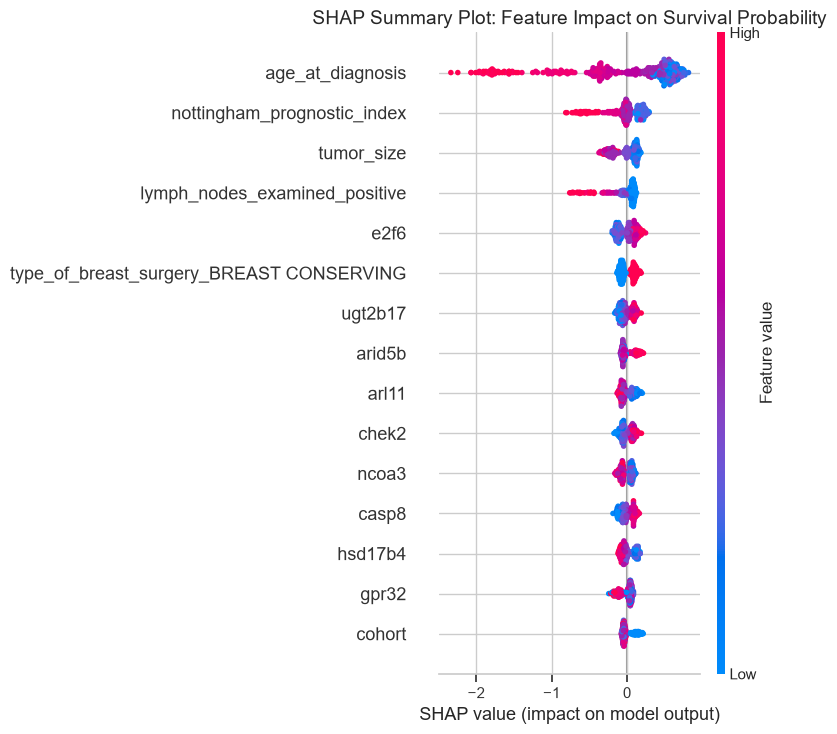

In [17]:
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

# 1. Train an XGBoost Classifier
# XGBoost generally outperforms Random Forest on tabular data by sequentially minimizing errors
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,              # Keep shallow to prevent overfitting the high-dimensional noise
    subsample=0.8,
    colsample_bytree=0.5,     # Randomly sample features to force the model to look beyond age/tumor_size
    objective='binary:logistic',
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(), # Handle class imbalance
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_clean, y_train)

# 2. Evaluate XGBoost Performance
y_pred_xgb = xgb_model.predict(X_test_clean)
y_proba_xgb = xgb_model.predict_proba(X_test_clean)[:, 1]

print("\n--- Gradient Boosting Performance (XGBoost) ---")
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_xgb):.4f}")

# 3. Model Interpretability with SHAP
print("\nCalculating SHAP values (this may take a moment)...")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_clean)

# 4. Plot SHAP Summary
plt.figure(figsize=(12, 8))
plt.title("SHAP Summary Plot: Feature Impact on Survival Probability", fontsize=14)
shap.summary_plot(shap_values, X_test_clean, max_display=15, show=False)
plt.tight_layout()
plt.show()

The transition to an XGBoost classifier successfully elevated the ROC-AUC score to 0.7466, confirming that gradient boosting captures critical non-linear interactions within the clinical and genomic data that the linear baseline missed.

Patient 0 - Actual Survival: 0 | Predicted Probability: 0.1902


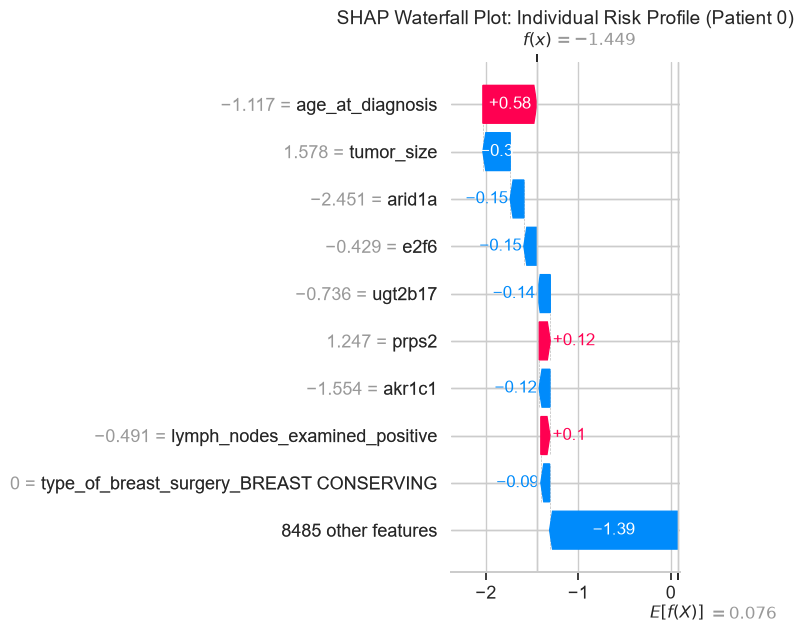

In [18]:
# 1. Local Interpretability: Explaining a Single Patient's Prediction
# Select a specific patient from the test set (e.g., the first patient, index 0)
patient_index = 0
patient_data = X_test_clean.iloc[[patient_index]]
actual_outcome = y_test.iloc[patient_index]
predicted_prob = xgb_model.predict_proba(patient_data)[0, 1]

print(f"Patient {patient_index} - Actual Survival: {actual_outcome} | Predicted Probability: {predicted_prob:.4f}")

# 2. Generate a Waterfall Plot for the specific patient
# The explainer was already created in the previous block
shap_values_local = explainer(patient_data)

plt.figure(figsize=(10, 6))
plt.title(f"SHAP Waterfall Plot: Individual Risk Profile (Patient {patient_index})", fontsize=14)
# We plot the SHAP values for the positive class (survival)
shap.plots.waterfall(shap_values_local[0], max_display=10, show=False)
plt.tight_layout()
plt.show()

Running UMAP dimensionality reduction (this may take a minute)...


c:\Users\renan\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\renan\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


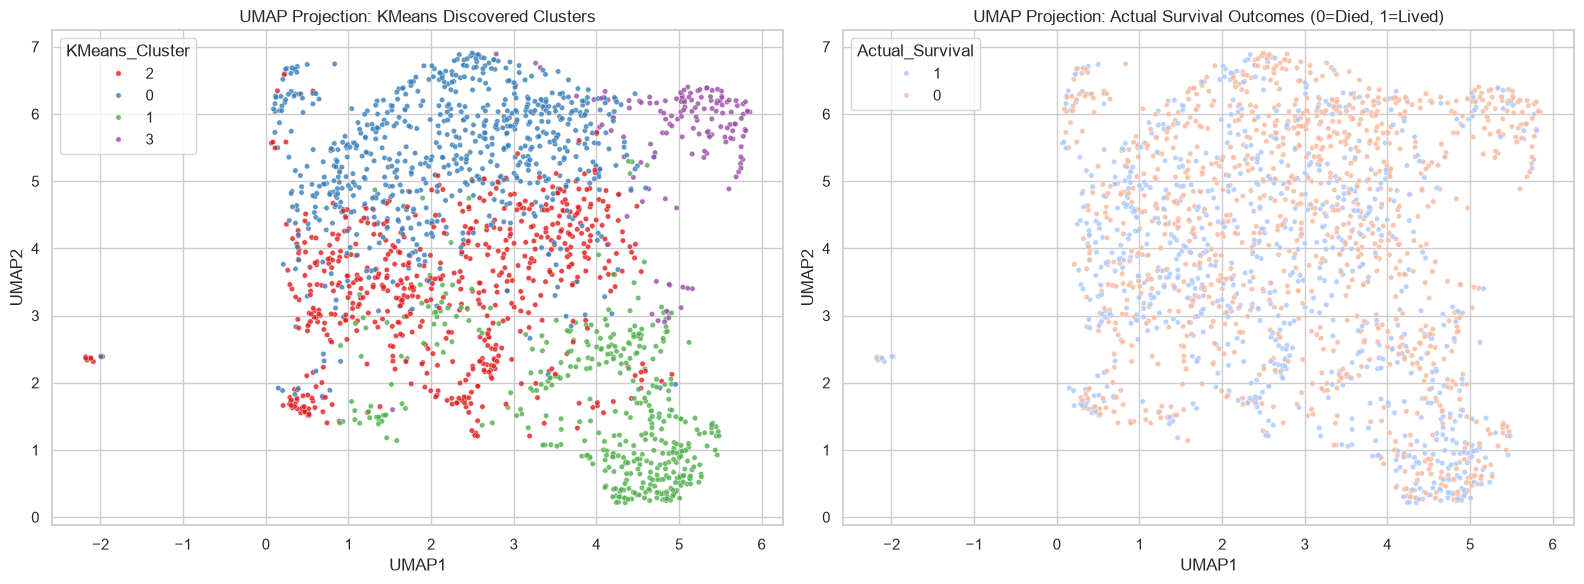

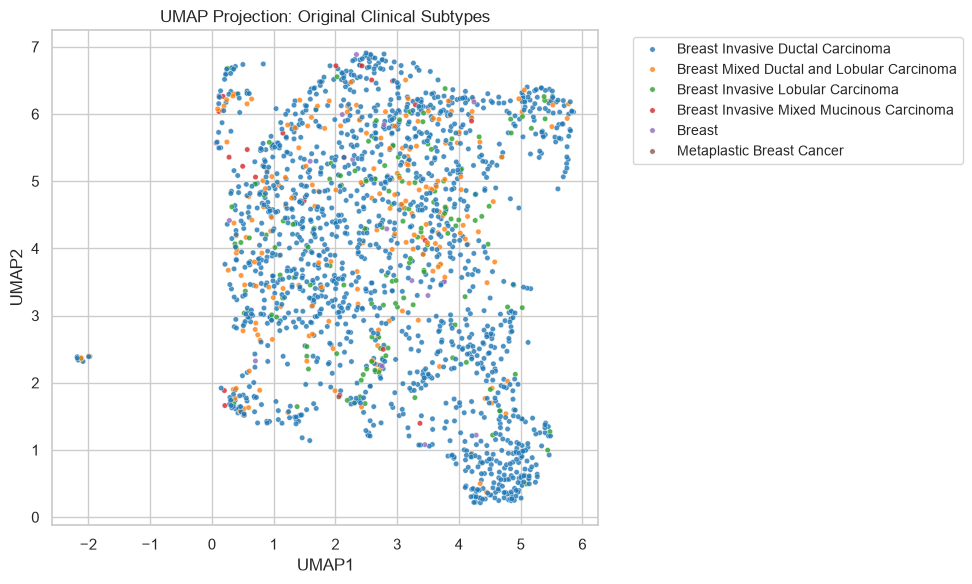

In [20]:
import umap
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("Running UMAP dimensionality reduction (this may take a minute)...")
# Manifold Learning with UMAP
# Compress the high-dimensional clean dataset (X_clean) into 2D space
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(X_clean)

# 2. Unsupervised Clustering with KMeans
# We will search for 4 clusters, conceptually mirroring the 4 main intrinsic breast cancer subtypes
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_clean)

# 3. Compile the projections and labels into a new DataFrame for plotting
plot_df = pd.DataFrame(embedding, columns=['UMAP1', 'UMAP2'])
plot_df['KMeans_Cluster'] = clusters.astype(str)
plot_df['Actual_Survival'] = y.values.astype(str)

# include the original cancer subtype labels if they exist in the raw dataframe
if 'cancer_type_detailed' in df.columns:
    # Ensure index alignment by extracting raw values
    plot_df['Clinical_Subtype'] = df.loc[X_clean.index, 'cancer_type_detailed'].values
else:
    plot_df['Clinical_Subtype'] = "N/A"

# visualize the Manifold
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# the algorithmic clusters discovered by KMeans
sns.scatterplot(
    data=plot_df, x='UMAP1', y='UMAP2', hue='KMeans_Cluster', 
    palette='Set1', s=15, alpha=0.8, ax=axes[0]
)
axes[0].set_title('UMAP Projection: KMeans Discovered Clusters')

# the actual survival outcomes mapped onto the same space
sns.scatterplot(
    data=plot_df, x='UMAP1', y='UMAP2', hue='Actual_Survival', 
    palette='coolwarm', s=15, alpha=0.8, ax=axes[1]
)
axes[1].set_title('UMAP Projection: Actual Survival Outcomes (0=Died, 1=Lived)')

plt.tight_layout()
plt.show()

# If original subtypes exist, see how they map to the UMAP space
if 'cancer_type_detailed' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=plot_df, x='UMAP1', y='UMAP2', hue='Clinical_Subtype', 
        palette='tab10', s=15, alpha=0.8
    )
    plt.title('UMAP Projection: Original Clinical Subtypes')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
    plt.tight_layout()
    plt.show()

The UMAP projections provide a visually conclusion to your dataset analysis, revealing why predicting survival outcomes in this cohort is fundamentally challenging.

The UMAP projection does not separate the patients into highly distinct, isolated "islands". Instead, it forms a large, mostly continuous manifold, indicating that the clinical and genomic variance among these patients exists on a continuous spectrum rather than as strictly separated biological categories.  

When mapping actual survival onto the UMAP space, the outcomes (0 and 1) are heavily intermingled across the entire projection. There are no localized clusters where patients strictly survived or strictly died. This perfectly illustrates why your non-linear XGBoost model achieved a ~0.74 ROC-AUC rather than a >0.90; the classes are deeply entangled within the high-dimensional space.  

The KMeans algorithm successfully partitioned the continuous space into four clusters. However, comparing this to the original clinical subtypes shows that the dominant classification—Breast Invasive Ductal Carcinoma—spans nearly the entire manifold and overlaps heavily with other subtypes. The unsupervised genomic clusters do not perfectly mirror the traditional clinical labels